# Model decision: paired uncertainty and operational readiness

Compare the Transformer and boosted trees using the **same forward-evaluated quarters and frozen thresholds**. Random Forest is included as a reference. The primary endpoint is onsets caught at least 15 minutes early under the 4 wrong-alert-hours/day calibration policy; the episode-budget policy and non-recurrent onset recall are secondary.

We resample calendar weeks within each evaluation quarter, keeping all stations and available days together and using identical draws for both models. Daily resampling is a sensitivity analysis. Intervals condition on the saved fits and selected thresholds: they do not include retraining, threshold-selection uncertainty, feature selection or future regime shifts. These are exploratory development results, not holdout estimates.


## Findings from the saved run

Under the **4 wrong-alert-hours/day calibration policy**, Transformer caught 53.2% of onsets at least 15 minutes early versus 52.7% for boosted trees. The paired weekly difference is **+0.50 percentage points (95% interval: -0.66 to +1.57)**. This does not clearly distinguish their detection performance, and does not demonstrate equivalence.

Transformer generated **2.08 fewer false episodes/day** (interval: 1.62 to 2.58 fewer) and **0.116 fewer wrong-alert hours/day** (interval: 0.025 to 0.214 fewer). Its realized burden was lower under this frozen policy; it still breached the duration budget in one quarter, as recorded in forward validation. Confidence intervals for average differences do not guarantee a future-quarter budget.

Under the **episode-budget policy**, Transformer detected 6.33 percentage points more onsets (interval: +5.19 to +7.43), but generated 0.254 additional wrong-alert hours/day (interval: +0.175 to +0.330). The choice of warning-cost definition affects the operational tradeoff. These comparisons do not impose exactly equal realized cost.

For non-recurrent onsets under the duration policy, the models caught only 4.9% and 3.4%. The weekly interval for their difference touches zero; the daily interval excludes zero. Conclusions about this small subgroup are sensitive to the dependence assumption.

**Operational measurements remain pending.** Neither selected run contains its fitted checkpoint here. The Transformer configuration records a different shared-feature source hash; its three model/history/training source hashes match the local files. That mismatch does not establish different feature values, but it must be explained before claiming exact reproduction. Historical Transformer logs total 60 epochs and about 4.84 hours of epoch execution across six folds; this excludes preprocessing/inference and has no matched boosted-tree timing, so it is not a speed comparison.

The evidence favors keeping both models as finalists. Recover their original artifacts, resolve feature-source provenance, and measure deployment cost before selecting the final model. The final holdout stays untouched. See the [operational benchmark protocol](../../../src/analysis/operational_benchmark_protocol.md) for the exact exports and measurements.


In [1]:
from pathlib import Path
import sys, json, hashlib
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
            if (p / 'notebooks/safeflow_features.py').is_file())
sys.path[:0] = [str(ROOT), str(ROOT / 'notebooks')]
import safeflow_features as sf
from src.analysis.early_warning_errors import align_predictions, forward_budget_validation, warning_leads
EPISODE_BUDGET, HOURS_BUDGET = 20, 4
# Reuse a completed, provenance-checked all-model analysis; override explicitly if needed.
SOURCE_RUN = None
candidates = sorted((ROOT / 'results/error_analysis_models').glob('*/manifest.json'), reverse=True)
if SOURCE_RUN is None:
    SOURCE_RUN = next(p.parent for p in candidates if len(json.loads(p.read_text())['input_provenance']) == 3)
manifest = json.loads((SOURCE_RUN / 'manifest.json').read_text())
assert not manifest['holdout_used']
assert hashlib.sha256((ROOT / 'notebooks/safeflow_features.py').read_bytes()).hexdigest() == manifest['shared_code_sha256']
cache = ROOT / 'results/error_analysis_models/cache' / ('validation_context_' + manifest['context_signature'][:16] + '.parquet')
if not cache.exists():
    raise FileNotFoundError('Run analysis/error_analysis_models.ipynb first to build its development context cache.')
reference = pd.read_parquet(cache).sort_values(['station','timestamp']).reset_index(drop=True)
assert reference.timestamp.max() < pd.Timestamp('2025-07-01')
OUT = ROOT / 'results/model_decision_analysis' / datetime.now().strftime('%Y%m%d_%H%M%S_%f')
OUT.mkdir(parents=True)
print('Source analysis:', SOURCE_RUN)
print('Validation rows:', len(reference), '| output:', OUT)


Source analysis: C:\Erdos\Project\safeflow\results\error_analysis_models\20261104_095913_315957
Validation rows: 2898000 | output: C:\Erdos\Project\safeflow\results\model_decision_analysis\20261104_104058_694019


In [2]:
probabilities = {'Timetable': reference.typical_congestion_30.fillna(0).to_numpy()}
for model, provenance in manifest['input_provenance'].items():
    files = []
    for saved, expected_hash in zip(provenance['files'], provenance['sha256'], strict=True):
        # Export paths are portable across machines: retain the repository-relative src/... suffix.
        normalized = saved.replace('\\', '/')
        relative = 'src/' + normalized.split('/src/', 1)[1]
        path = ROOT / relative
        assert hashlib.sha256(path.read_bytes()).hexdigest() == expected_hash, path
        files.append(pd.read_parquet(path))
    probabilities[model] = align_predictions(reference, pd.concat(files, ignore_index=True), provenance['probability_column'])
    print('Aligned and verified:', model, flush=True)


Aligned and verified: Random Forest
Aligned and verified: Transformer
Aligned and verified: Boosted trees (29)


In [3]:
from src.analysis.paired_uncertainty import paired_bootstrap
FORWARD_RUN = next(p.parent for p in sorted((ROOT / 'results/forward_warning_budget_validation').glob('*/manifest.json'),reverse=True))
forward_manifest = json.loads((FORWARD_RUN / 'manifest.json').read_text())
assert forward_manifest['input_provenance'] == manifest['input_provenance']
assert forward_manifest['context_signature'] == manifest['context_signature']
assert not forward_manifest['holdout_used']
policies = pd.read_csv(FORWARD_RUN / 'quarterly_policies.csv')
forward_summary = pd.read_csv(FORWARD_RUN / 'summary.csv')
MODELS = ['Transformer','Boosted trees (29)','Random Forest']
REPETITIONS, SEED = 5000, 42
print('Frozen policies:', FORWARD_RUN, '| paired replicates:', REPETITIONS)


Frozen policies: C:\Erdos\Project\safeflow\results\forward_warning_budget_validation\20261104_102956_926783 | paired replicates: 5000


## Reconstruct paired daily outcomes

False-warning episodes are attributed to the day on which they begin. Wrong duration counts known-negative 5-minute readings. Detection uses the earliest warning in the preceding 30 minutes; success requires at least 15 minutes of lead. Non-recurrent means the fold's training-only usual congestion rate at onset minus 15 minutes is below 10%. Unknown recurrence is excluded from that subgroup denominator, but stays in the overall population.


In [4]:
daily_parts=[]
for model in MODELS:
    p=probabilities[model]
    for row in policies.loc[policies.model.eq(model)].itertuples():
        selected=reference.fold.eq(row.fold).to_numpy()
        test=reference.loc[selected].reset_index(drop=True)
        score=p[selected]
        wrong=(score>=row.threshold)&test.y_known.to_numpy()&~test.y.to_numpy()
        adjacent=np.r_[False, (test.station.to_numpy()[1:]==test.station.to_numpy()[:-1]) &
            (np.diff(test.timestamp.to_numpy(dtype='datetime64[ns]'))==np.timedelta64(5,'m'))]
        starts=wrong & ~(np.r_[False,wrong[:-1]]&adjacent)
        day=pd.to_datetime(test.date).dt.normalize()
        costs=pd.DataFrame({'date':day,'wrong_rows':wrong.astype(int),'false_episodes':starts.astype(int)}).groupby('date').sum()
        onsets=test.loc[test.onset,['station','timestamp']].copy()
        leads=warning_leads(test,score,onsets,row.threshold)
        wanted=pd.MultiIndex.from_arrays([onsets.station,onsets.timestamp-pd.Timedelta(minutes=15)])
        recurrence=test.set_index(['station','timestamp']).typical_congestion_30.reindex(wanted).to_numpy()
        rare=np.isfinite(recurrence)&(recurrence<.1)
        events=pd.DataFrame(dict(date=onsets.timestamp.dt.normalize().to_numpy(),onsets=1,caught=(leads>=15).astype(int),rare_onsets=rare.astype(int),rare_caught=(rare&(leads>=15)).astype(int))).groupby('date').sum()
        daily=costs.join(events,how='left').fillna(0).reset_index()
        daily['days']=1
        daily['fold']=row.fold
        daily['model']=model
        daily['budget_type']=row.budget_type
        assert daily.onsets.sum()==row.onsets
        assert daily.caught.sum()==row.caught_count
        assert np.isclose(daily.false_episodes.sum()/len(daily),row.false_episodes_per_day)
        assert np.isclose(daily.wrong_rows.sum()*5/60/len(daily),row.wrong_alert_hours_per_day)
        daily_parts.append(daily)
    print('Verified daily reconstruction:',model,flush=True)
daily=pd.concat(daily_parts,ignore_index=True)
daily.to_csv(OUT/'daily_paired_counts.csv',index=False)
print('All daily sums match frozen-policy results.')


Verified daily reconstruction: Transformer
Verified daily reconstruction: Boosted trees (29)
Verified daily reconstruction: Random Forest
All daily sums match frozen-policy results.


## Paired confidence intervals

A positive detection difference favors the first model; a negative warning-cost difference favors it. Weekly resampling allows within-week temporal dependence and keeps spatial dependence across detectors. Splitting blocks at quarter boundaries preserves the evaluation design. Percentile 95% intervals are descriptive, with no multiplicity adjustment. An interval containing zero does not establish equivalence; it means this analysis does not clearly separate the models.


In [5]:
interval_parts=[]
for policy in ['duration','episodes']:
    d=daily.loc[daily.budget_type.eq(policy)]
    for opponent in ['Boosted trees (29)','Random Forest']:
        for block in ['week','day']:
            table,_=paired_bootstrap(d,'Transformer',opponent,block=block,repetitions=REPETITIONS,seed=SEED)
            table['budget_type']=policy
            interval_parts.append(table)
intervals=pd.concat(interval_parts,ignore_index=True)
intervals.to_csv(OUT/'paired_intervals.csv',index=False)
primary=intervals.loc[intervals.model_b.eq('Boosted trees (29)') & intervals.budget_type.eq('duration')].copy()
display(primary.round(5))
display(forward_summary.loc[forward_summary.model.isin(MODELS)].round(4))


,model_a,model_b,metric,block,difference,ci_low,ci_high,blocks,repetitions,seed,budget_type
0,Transformer,Boosted trees (29),catch_15min,week,0.00501,-0.00656,0.01567,69,5000,42,duration
1,Transformer,Boosted trees (29),false_episodes_per_day,week,-2.08307,-2.57918,-1.61752,69,5000,42,duration
2,Transformer,Boosted trees (29),wrong_alert_hours_per_day,week,-0.11555,-0.21447,-0.02478,69,5000,42,duration
3,Transformer,Boosted trees (29),rare_catch_15min,week,0.01496,0.00000,0.02996,69,5000,42,duration
4,Transformer,Boosted trees (29),catch_15min,day,0.00501,-0.00502,0.01495,313,5000,42,duration
5,Transformer,Boosted trees (29),false_episodes_per_day,day,-2.08307,-2.51765,-1.64529,313,5000,42,duration
6,Transformer,Boosted trees (29),wrong_alert_hours_per_day,day,-0.11555,-0.19143,-0.04047,313,5000,42,duration
7,Transformer,Boosted trees (29),rare_catch_15min,day,0.01496,0.00170,0.02899,313,5000,42,duration


,model,policy,onsets,catch_15min,false_episodes_per_day,wrong_alert_hours_per_day,quarters_over_budget,evaluated_quarters
2,Random Forest,episodes,7587,0.2297,17.7987,1.9886,0,5
3,Random Forest,duration,7587,0.4355,26.0927,3.4864,0,5
4,Transformer,episodes,7587,0.4626,17.3163,2.4276,1,5
5,Transformer,duration,7587,0.5321,21.1246,3.1941,1,5
6,Boosted trees (29),episodes,7587,0.3994,16.8978,2.1736,0,5
7,Boosted trees (29),duration,7587,0.5271,23.2077,3.3096,0,5


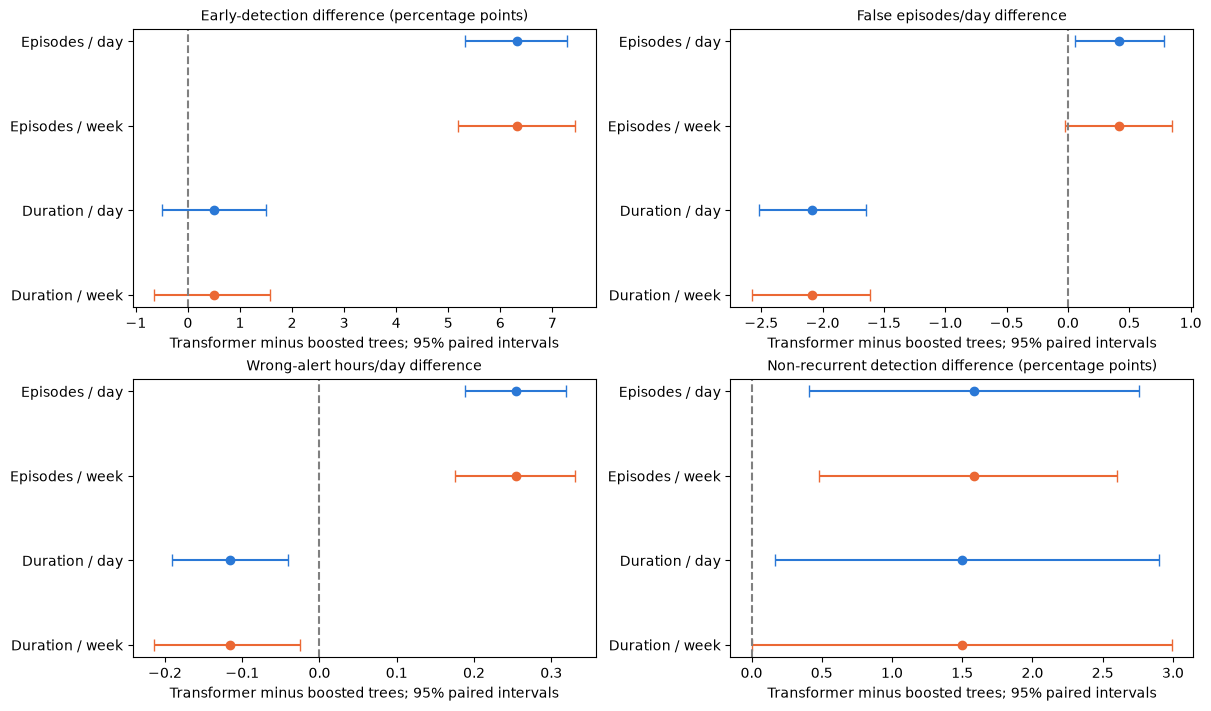

In [6]:
metrics=[('catch_15min','Early-detection difference (percentage points)',100),
         ('false_episodes_per_day','False episodes/day difference',1),
         ('wrong_alert_hours_per_day','Wrong-alert hours/day difference',1),
         ('rare_catch_15min','Non-recurrent detection difference (percentage points)',100)]
fig,axes=plt.subplots(2,2,figsize=(12,7),layout='constrained')
for ax,(metric,title,scale) in zip(axes.flat,metrics):
    for i,(policy,block) in enumerate([('duration','week'),('duration','day'),('episodes','week'),('episodes','day')]):
        r=intervals.loc[intervals.model_b.eq('Boosted trees (29)') & intervals.budget_type.eq(policy) & intervals.block.eq(block) & intervals.metric.eq(metric)].iloc[0]
        ax.errorbar(r.difference*scale,i,xerr=[[max(0,r.difference-r.ci_low)*scale],[max(0,r.ci_high-r.difference)*scale]],fmt='o',color='#eb6834' if block=='week' else '#2a78d6',capsize=4)
    ax.axvline(0,color='gray',linestyle='--')
    ax.set_yticks(range(4),['Duration / week','Duration / day','Episodes / week','Episodes / day'])
    ax.set_title(title,fontsize=10)
    ax.set_xlabel('Transformer minus boosted trees; 95% paired intervals')
fig.savefig(OUT/'paired_uncertainty.png',dpi=160)
plt.show()


## Operational evidence and gaps

We audit the actual selected run directories, not just model definitions. Saved prediction size is not model size. Training logs from another machine cannot establish a controlled speed comparison. Current code supports missing values through boosted-tree native routing or Transformer imputation and missing flags; that alone is not empirical evidence of robustness to a detector outage.

Both models use engineered lag/spatial features. The Transformer additionally consumes up to 24 historical feature vectors, while boosted trees consume one engineered vector. Transformer history is built lazily with padding when history is unavailable; this is an implementation requirement, not proof that all 24 observations are mandatory.


In [7]:
import re
operational=[]
source_audit=[]
for model in ['Transformer','Boosted trees (29)']:
    run=Path(manifest['input_provenance'][model]['files'][0].replace('\\','/')).parent.parent
    # Resolve run directory portably, just as for prediction exports.
    run=ROOT/('src/'+str(run).replace('\\','/').split('/src/',1)[1])
    extensions=['*.pt','*.pth'] if model=='Transformer' else ['*.joblib','*.pkl']
    checkpoints=[p for ext in extensions for p in run.rglob(ext)]
    required='model.pt (includes weights, architecture and preprocessing)' if model=='Transformer' else 'model.joblib plus exact ordered features'
    operational.append(dict(model=model,run=str(run.relative_to(ROOT)),checkpoints=len(checkpoints),
        checkpoint_bytes=sum(p.stat().st_size for p in checkpoints) if checkpoints else np.nan,
        logical_features=29,encoded_channels=46 if model=='Transformer' else 29,
        history_vectors=24 if model=='Transformer' else 1,
        max_input_values=1104 if model=='Transformer' else 29,
        inference_benchmark='not measured: fitted checkpoint absent' if not checkpoints else 'checkpoint available; measurement required',
        missing_input_benchmark='not measured',required_artifact=required))
    config_path=run/('configuration.json' if model=='Transformer' else 'manifest.json')
    config=json.loads(config_path.read_text())
    recorded_files = config.get('source_hashes', {}) if model == 'Transformer' else {'safeflow_features.py': config.get('shared_code_sha256')}
    for filename, recorded in recorded_files.items():
        local = ROOT / ('notebooks' if filename == 'safeflow_features.py' else 'src/transformer') / filename
        local_hash = hashlib.sha256(local.read_bytes()).hexdigest()
        source_audit.append(dict(model=model,file=filename,recorded_sha256=recorded,
            local_sha256=local_hash,matches_local=recorded==local_hash))
operational=pd.DataFrame(operational)
source_audit=pd.DataFrame(source_audit)
operational.to_csv(OUT/'operational_readiness.csv',index=False)
source_audit.to_csv(OUT/'source_audit.csv',index=False)
display(operational)
display(source_audit)
# Historical timing evidence: training epoch times only, excluding preparation and inference.
nb=json.loads((ROOT/'notebooks/train_transformer.ipynb').read_text())
text='\n'.join(''.join(o.get('text',[])) for c in nb['cells'] for o in c.get('outputs',[]))
seconds=[float(x) for x in re.findall(r'epoch \d+/\d+: BCE=[0-9.]+, ([0-9.]+)s',text)]
timing=pd.DataFrame([dict(model='Transformer',source='saved train_transformer.ipynb stdout',
    epoch_records=len(seconds),epoch_seconds_sum=sum(seconds) if seconds else np.nan,
    comparable_hardware=False,scope='historical epoch time only; no matched boosted timing')])
timing.to_csv(OUT/'historical_timing_evidence.csv',index=False)
display(timing)


,model,run,checkpoints,checkpoint_bytes,logical_features,encoded_channels,history_vectors,max_input_values,inference_benchmark,missing_input_benchmark,required_artifact
0,Transformer,src\transformer\results\transformer_29_feature...,0,NaN,29,46,24,1104,not measured: fitted checkpoint absent,not measured,"model.pt (includes weights, architecture and p..."
1,Boosted trees (29),src\boosted_trees\results\boosted_trees_29_fea...,0,NaN,29,29,1,29,not measured: fitted checkpoint absent,not measured,model.joblib plus exact ordered features


,model,file,recorded_sha256,local_sha256,matches_local
0,Transformer,safeflow_features.py,0c1fff5e99aeacb9f7f9d0f5cbfcefba0da759329519f8...,09fee9268cfabcd7a9db64a86a7759f082eac6a14e2c51...,False
1,Transformer,safeflow_transformer.py,fce12ef6170963dfb070f29a65418c683744aa88346f3e...,fce12ef6170963dfb070f29a65418c683744aa88346f3e...,True
2,Transformer,build_history_windows.py,3a4ece19cc88543d1e347413704bb0df01e28cc1467f01...,3a4ece19cc88543d1e347413704bb0df01e28cc1467f01...,True
3,Transformer,transformer_training.py,4554b4d42d91f01b174dd14761b420a5ebcbf83dc7f411...,4554b4d42d91f01b174dd14761b420a5ebcbf83dc7f411...,True
4,Boosted trees (29),safeflow_features.py,09fee9268cfabcd7a9db64a86a7759f082eac6a14e2c51...,09fee9268cfabcd7a9db64a86a7759f082eac6a14e2c51...,True


,model,source,epoch_records,epoch_seconds_sum,comparable_hardware,scope
0,Transformer,saved train_transformer.ipynb stdout,60,17425.7,False,historical epoch time only; no matched boosted...


## What is needed for a deployment benchmark

Export the **last development fold (2025 Q2)** Transformer `model.pt` and boosted-tree `model.joblib` from the exact runs audited above; the current training code already saves them locally. Also supply the original Transformer feature source or a reproducible source snapshot to explain its different recorded hash. Matching feature names and aligned outcomes do not prove identical feature computation.

Once available, benchmark both on the same CPU, thread limit and development endpoints, using batches of 1 and 46 stations. Verify reproduction of saved probabilities before timing. Report warm median/p95 latency, feature/history preparation separately, throughput, serialized checkpoint size and process peak memory. For robustness, freeze thresholds and perturb identical development detector/time blocks: mask upstream/downstream features and simulate 5/15/30-minute outages using the original preprocessing, without refitting. Report detection and warning costs together. These measurements are pending; no performance or memory numbers are inferred from architecture alone.

A practical choice should combine the paired uncertainty with measured operating cost. If models remain close, choose the simpler system only after validating its operational requirements. Keep the final holdout closed until the evaluation policy is frozen.


In [8]:
assert daily.date.max() < pd.Timestamp('2025-07-01')
assert set(daily.model)==set(MODELS)
record=dict(source_forward_run=str(FORWARD_RUN.relative_to(ROOT)),source_analysis_run=str(SOURCE_RUN.relative_to(ROOT)),
    input_provenance=manifest['input_provenance'],context_signature=manifest['context_signature'],
    holdout_used=False,retrained=False,thresholds_reselected=False,repetitions=REPETITIONS,seed=SEED,
    resampling='paired calendar weeks within quarters; day sensitivity',
    uncertainty_scope='conditional on saved fits and frozen thresholds; no model/feature-selection uncertainty',
    primary='Transformer minus boosted trees; early detection under duration-budget policy',
    operational_benchmark='pending fitted artifacts',source_audit=source_audit.to_dict('records'))
(OUT/'manifest.json').write_text(json.dumps(record,indent=2),encoding='utf-8')
print('Saved uncertainty tables, chart, operational audit and provenance:',OUT)


Saved uncertainty tables, chart, operational audit and provenance: C:\Erdos\Project\safeflow\results\model_decision_analysis\20261104_104058_694019
